In [ ]:
import csv
import shutil
import pickle
from pathlib import Path
from scipy.io import wavfile
import matplotlib.pyplot as plt
import librosa
import librosa.display
import IPython.display as ipd
%matplotlib inline

In [13]:

PHYSIONET_ROOT = Path(r"D:\MLOps_Project\physionet_dataset")   
PASCAL_ROOT    = Path(r"D:\MLOps_Project\pascal_dataset")       
OUT_ROOT       = Path(r"D:\MLOps_Project\ourdataset")

In [14]:
physionet_normal = []
physionet_abnormal = []

for letter in "abcdef":
    folder = PHYSIONET_ROOT / f"training-{letter}"
    with open(folder / "REFERENCE.csv") as f:
        for row in csv.reader(f):
            if len(row) < 2:
                continue
            record_id, code_ = row[0], row[1]
            wav_path = folder / f"{record_id}.wav"
            if not wav_path.exists():
                continue

            if code_ == "-1":
                physionet_normal.append(wav_path)
            else:
                physionet_abnormal.append(wav_path)

print("PhysioNet normal:", len(physionet_normal))
print("PhysioNet abnormal:", len(physionet_abnormal))

PhysioNet normal: 2575
PhysioNet abnormal: 665


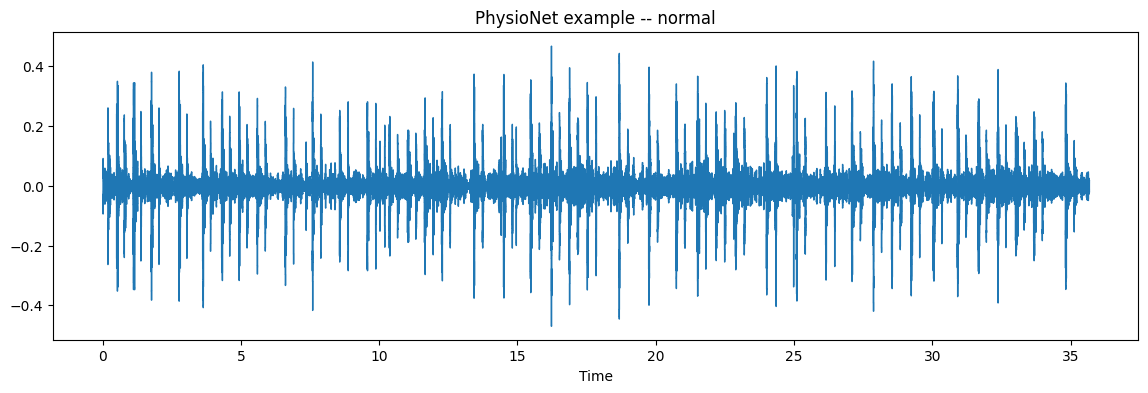

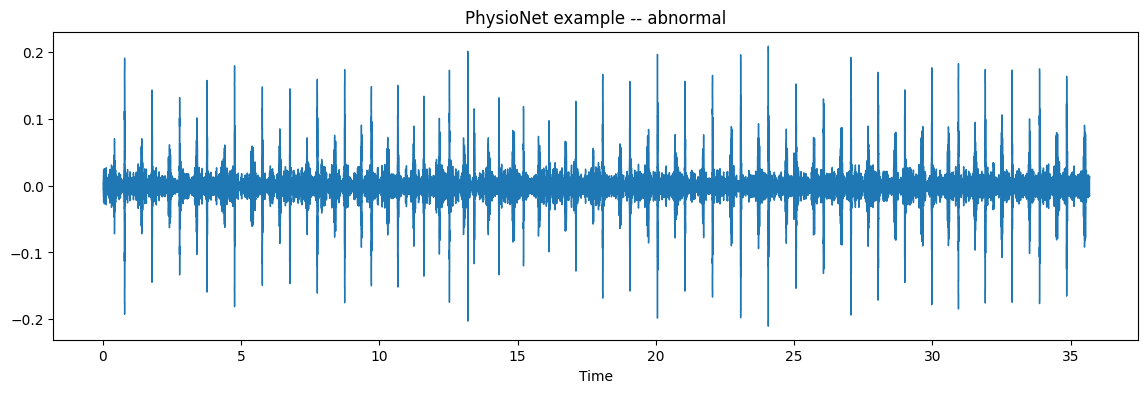

In [15]:
x, sr = librosa.load(physionet_normal[0], sr=None)   # sr=None keeps the file's original rate
plt.figure(figsize=(14, 4))
librosa.display.waveshow(x, sr=sr)
plt.title("PhysioNet example -- normal")
plt.show()
ipd.display(ipd.Audio(physionet_normal[0]))

x, sr = librosa.load(physionet_abnormal[0], sr=None)
plt.figure(figsize=(14, 4))
librosa.display.waveshow(x, sr=sr)
plt.title("PhysioNet example -- abnormal")
plt.show()
ipd.display(ipd.Audio(physionet_abnormal[0]))

In [16]:
pascal_normal = []
pascal_murmur = []
pascal_extrastole = []

for wav_path in PASCAL_ROOT.rglob("*.wav"):
    name = wav_path.stem.lower()
    if name.startswith("normal"):
        pascal_normal.append(wav_path)
    elif name.startswith("murmur"):
        pascal_murmur.append(wav_path)
    elif name.startswith("extrastole"):
        pascal_extrastole.append(wav_path)
    # else: artifact, extrahls, etc. -- not needed here

print("Pascal normal:", len(pascal_normal))
print("Pascal murmur:", len(pascal_murmur))
print("Pascal extrastole:", len(pascal_extrastole))

pascal_abnormal = pascal_murmur + pascal_extrastole
print("Pascal abnormal (murmur + extrastole):", len(pascal_abnormal))

Pascal normal: 351
Pascal murmur: 129
Pascal extrastole: 46
Pascal abnormal (murmur + extrastole): 175


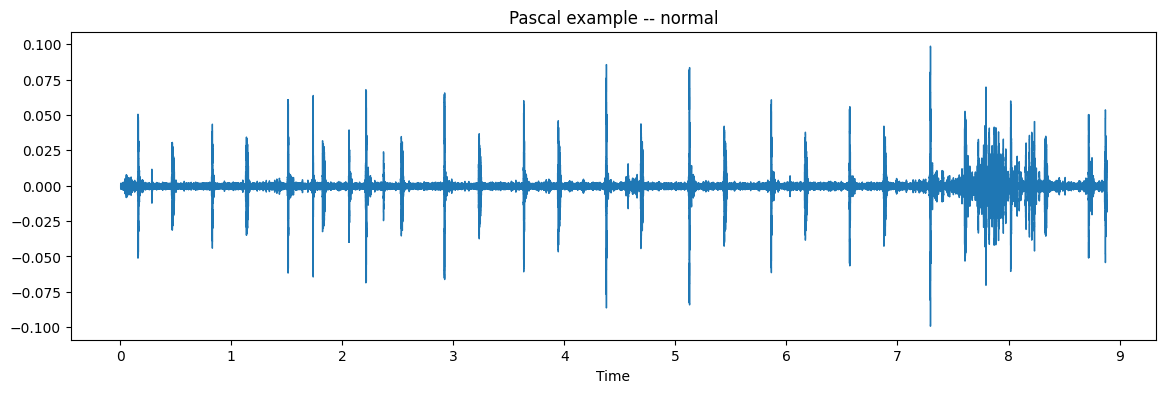

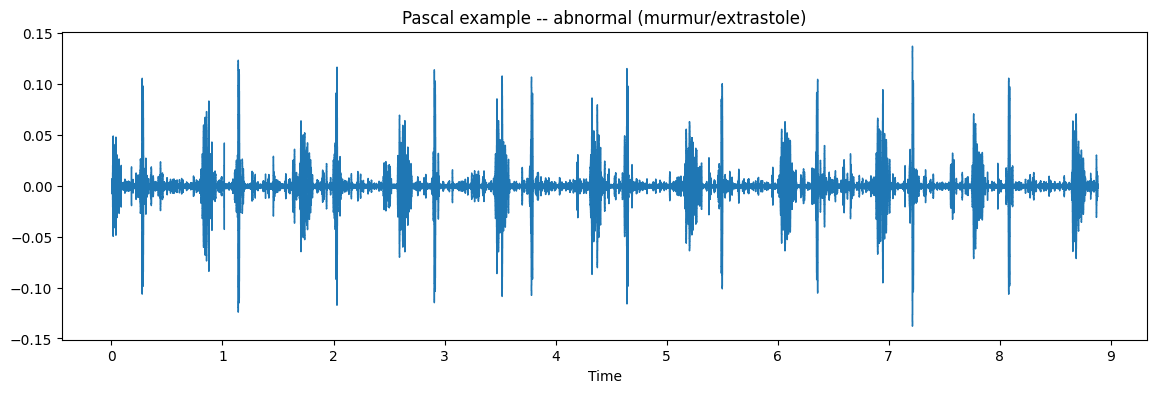

In [17]:
x, sr = librosa.load(pascal_normal[0], sr=None)
plt.figure(figsize=(14, 4))
librosa.display.waveshow(x, sr=sr)
plt.title("Pascal example -- normal")
plt.show()
ipd.display(ipd.Audio(pascal_normal[0]))

x, sr = librosa.load(pascal_abnormal[0], sr=None)
plt.figure(figsize=(14, 4))
librosa.display.waveshow(x, sr=sr)
plt.title("Pascal example -- abnormal (murmur/extrastole)")
plt.show()
ipd.display(ipd.Audio(pascal_abnormal[0]))

In [18]:
normal_dir = OUT_ROOT / "train" / "normal"
abnormal_dir = OUT_ROOT / "train" / "abnormal"
normal_dir.mkdir(parents=True, exist_ok=True)
abnormal_dir.mkdir(parents=True, exist_ok=True)

for wav_path in physionet_normal + pascal_normal:
    shutil.copy(wav_path, normal_dir / wav_path.name)

for wav_path in physionet_abnormal + pascal_abnormal:
    shutil.copy(wav_path, abnormal_dir / wav_path.name)

print("normal:", len(list(normal_dir.glob("*.wav"))))
print("abnormal:", len(list(abnormal_dir.glob("*.wav"))))

normal: 2926
abnormal: 840


In [19]:
def get_durations(folder):
    durations = []
    for wav_path in folder.glob("*.wav"):
        sr, data = wavfile.read(wav_path)
        durations.append(len(data) / sr)
    return durations

durations_abnormal = get_durations(abnormal_dir)
durations_normal = get_durations(normal_dir)

print("abnormal:", len(durations_abnormal))
print("normal:", len(durations_normal))

abnormal: 840
normal: 2926


In [20]:
with open("wavs_duration_abnormal_train.data", "wb") as f:
    pickle.dump(durations_abnormal, f)
with open("wavs_duration_normal_train.data", "wb") as f:
    pickle.dump(durations_normal, f)

print("saved.")
print("abnormal durations (first 10, in seconds):", durations_abnormal[:10])
print("normal durations (first 10, in seconds):", durations_normal[:10])

saved.
abnormal durations (first 10, in seconds): [35.666, 20.8285, 30.72, 35.5965, 35.666, 20.759, 35.8055, 35.736, 35.666, 35.736]
normal durations (first 10, in seconds): [35.666, 35.8055, 35.5965, 30.8595, 30.79, 30.8595, 31.138, 31.138, 30.8595, 30.72]


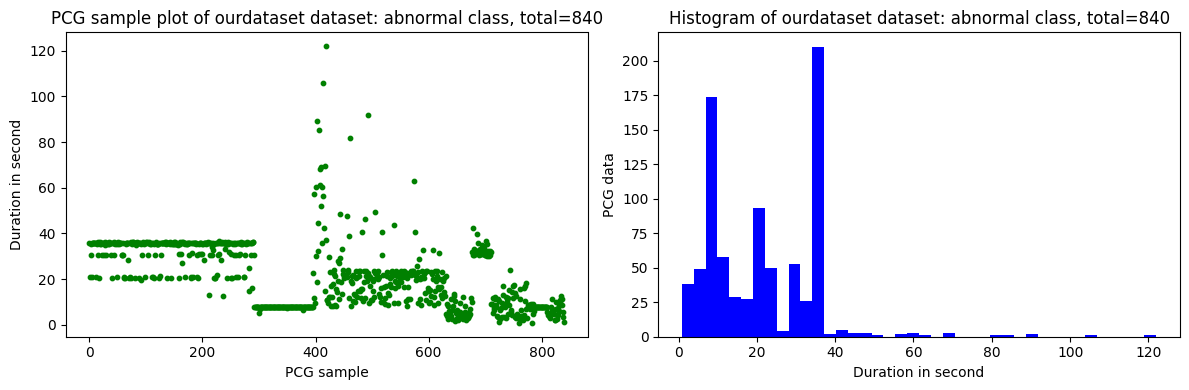

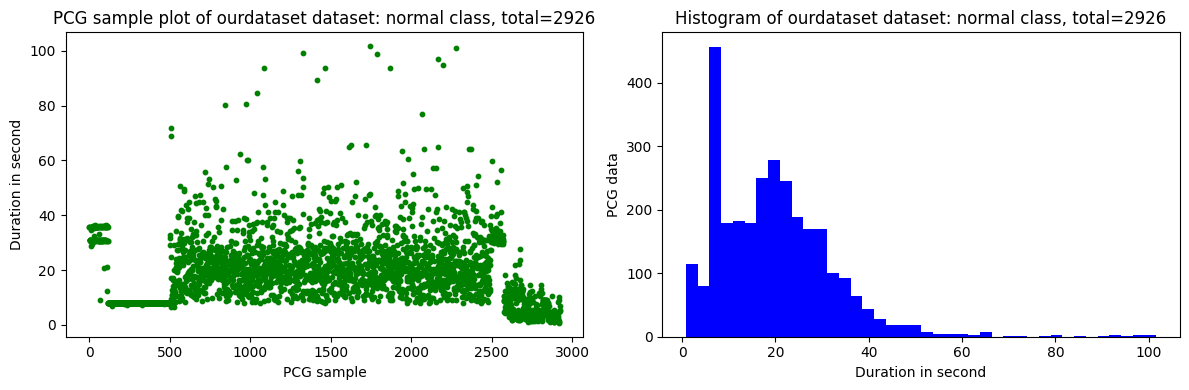

In [21]:
def plot_duration(durations, name):
    n = len(durations)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].scatter(range(n), durations, color="green", s=10)
    axes[0].set_title(f"PCG sample plot of ourdataset dataset: {name} class, total={n}")
    axes[0].set_xlabel("PCG sample")
    axes[0].set_ylabel("Duration in second")

    axes[1].hist(durations, bins=40, color="blue")
    axes[1].set_title(f"Histogram of ourdataset dataset: {name} class, total={n}")
    axes[1].set_xlabel("Duration in second")
    axes[1].set_ylabel("PCG data")

    plt.tight_layout()
    plt.show()

plot_duration(durations_abnormal, "abnormal")
plot_duration(durations_normal, "normal")

In [31]:
import numpy as np
from sklearn.neighbors import KernelDensity

In [32]:
def signal_to_noise(signal):
    norm = signal / np.max(np.abs(signal))
    return 0 if np.std(norm) == 0 else np.mean(norm) / np.std(norm)

def get_snrs(folder):
    snrs = []
    for wav_path in folder.glob("*.wav"):
        sr, data = wavfile.read(wav_path)
        snrs.append(signal_to_noise(data.astype(float)))
    return snrs

snr_abnormal = get_snrs(abnormal_dir)
snr_normal = get_snrs(normal_dir)

print("abnormal:", len(snr_abnormal))
print("normal:", len(snr_normal))

abnormal: 840
normal: 2926


In [33]:
with open("snr_abnormal_train.data", "wb") as f:
    pickle.dump(snr_abnormal, f)
with open("snr_normal_train.data", "wb") as f:
    pickle.dump(snr_normal, f)

print("saved.")
print("abnormal SNR (first 10):", snr_abnormal[:10])
print("normal SNR (first 10):", snr_normal[:10])

saved.
abnormal SNR (first 10): [np.float64(-0.0011135751954728956), np.float64(-0.00198363029074282), np.float64(-0.007060095552352819), np.float64(-0.0006627680079621069), np.float64(-0.0004634205594701138), np.float64(0.0003133533708640958), np.float64(-0.001493580488116971), np.float64(-0.002045198179960108), np.float64(-0.003165258077486665), np.float64(-0.0004632570020918585)]
normal SNR (first 10): [np.float64(-0.00042226412787212635), np.float64(-0.0032717846628010955), np.float64(-0.0008866162799553247), np.float64(-0.001303388225291124), np.float64(-0.00028018343908679165), np.float64(-0.0005129941199769319), np.float64(-0.0009253438411124822), np.float64(5.410368386686554e-05), np.float64(-0.00017615185038171607), np.float64(-0.0008534806067331898)]


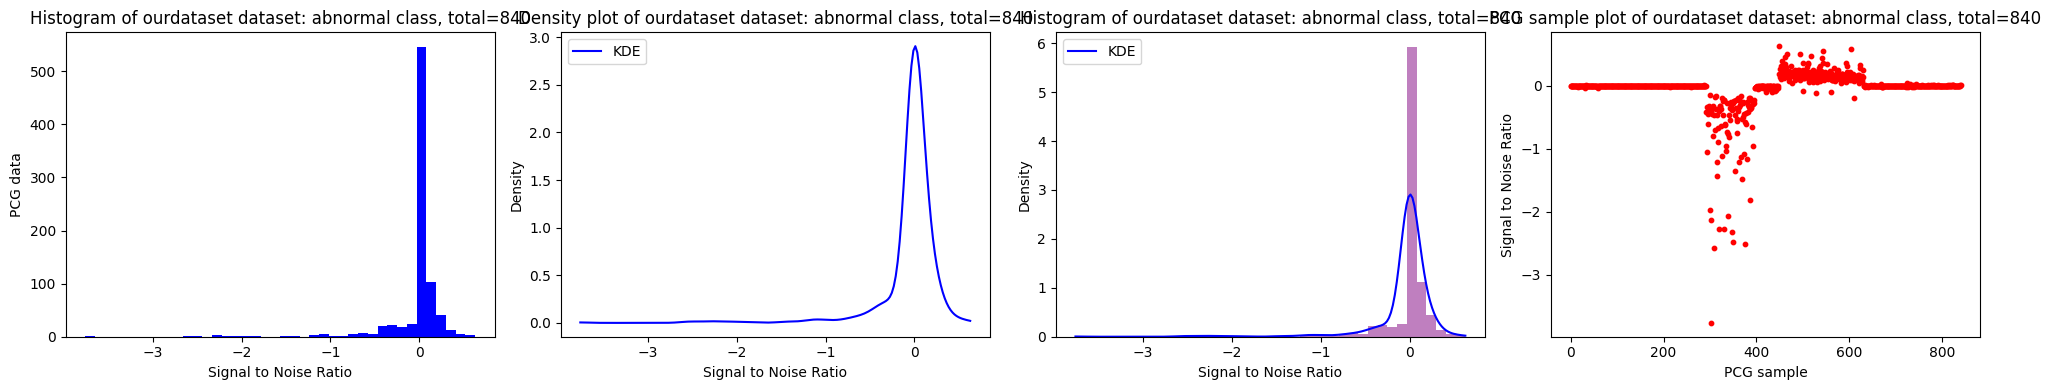

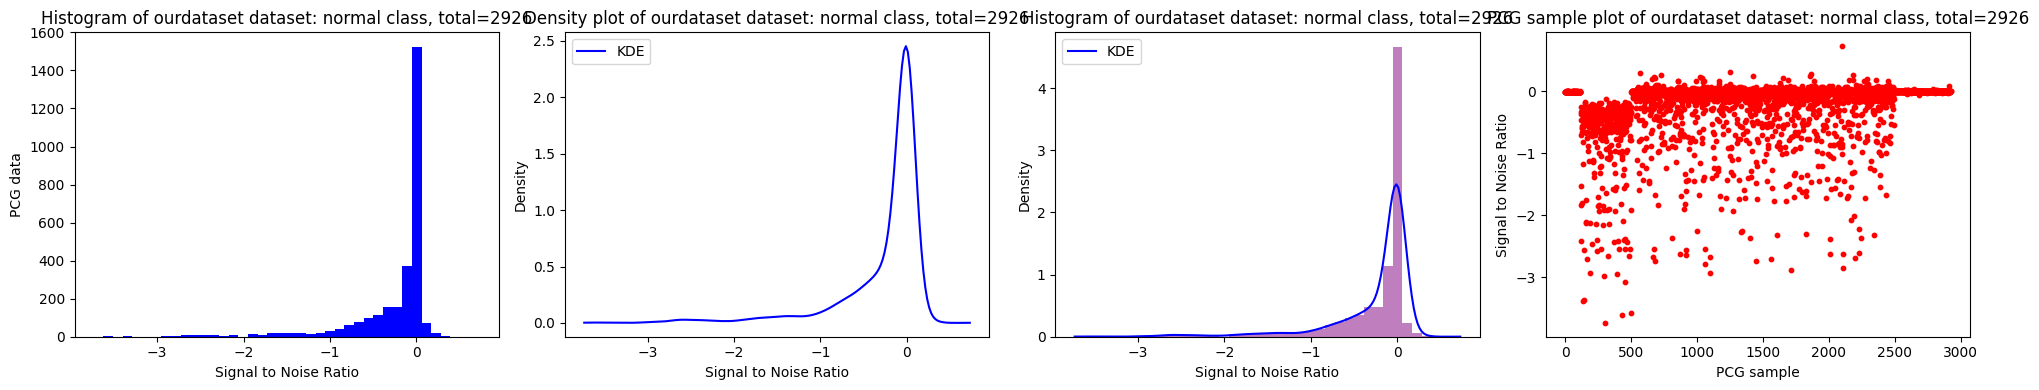

In [34]:
def plot_kde(values, ax, bandwidth=0.1):
    values = np.array(values).reshape(-1, 1)
    x_grid = np.linspace(values.min(), values.max(), 200).reshape(-1, 1)
    kde = KernelDensity(kernel="gaussian", bandwidth=bandwidth).fit(values)
    density = np.exp(kde.score_samples(x_grid))
    ax.plot(x_grid, density, color="blue", label="KDE")

def plot_snr(snrs, name):
    n = len(snrs)
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    axes[0].hist(snrs, bins=40, color="blue")
    axes[0].set_title(f"Histogram of ourdataset dataset: {name} class, total={n}")
    axes[0].set_xlabel("Signal to Noise Ratio")
    axes[0].set_ylabel("PCG data")

    plot_kde(snrs, axes[1])
    axes[1].set_title(f"Density plot of ourdataset dataset: {name} class, total={n}")
    axes[1].set_xlabel("Signal to Noise Ratio")
    axes[1].set_ylabel("Density")
    axes[1].legend()

    axes[2].hist(snrs, bins=40, color="purple", alpha=0.5, density=True)
    plot_kde(snrs, axes[2])
    axes[2].set_title(f"Histogram of ourdataset dataset: {name} class, total={n}")
    axes[2].set_xlabel("Signal to Noise Ratio")
    axes[2].set_ylabel("Density")
    axes[2].legend()

    axes[3].scatter(range(n), snrs, color="red", s=10)
    axes[3].set_title(f"PCG sample plot of ourdataset dataset: {name} class, total={n}")
    axes[3].set_xlabel("PCG sample")
    axes[3].set_ylabel("Signal to Noise Ratio")

    plt.tight_layout()
    plt.show()

plot_snr(snr_abnormal, "abnormal")
plot_snr(snr_normal, "normal")

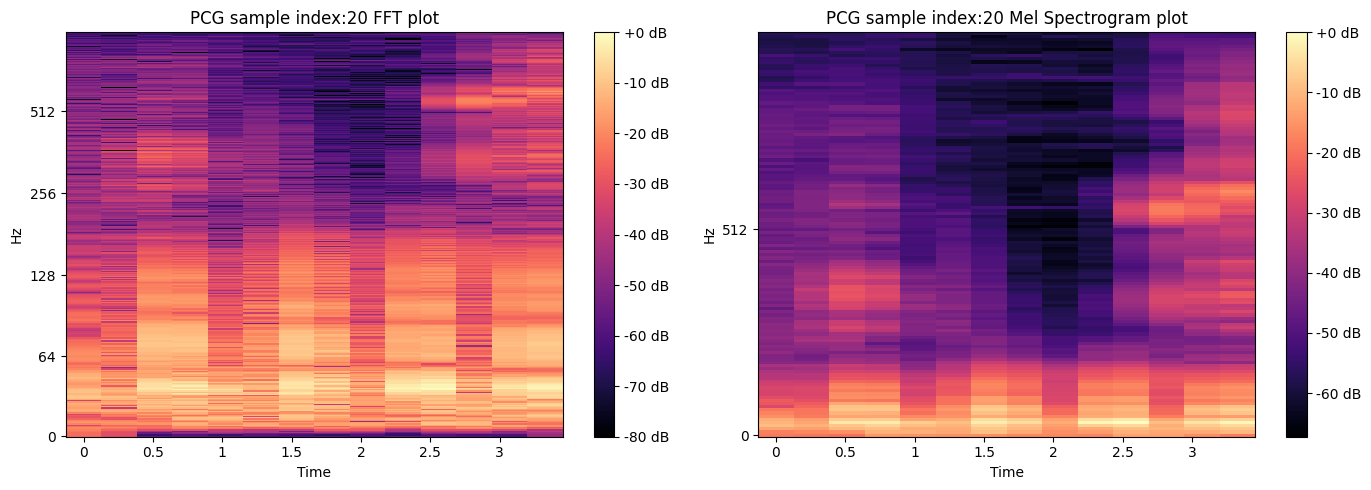

In [35]:
# one example file -- PCG sample index 20
example_files = sorted(normal_dir.glob("*.wav"))
example_path = example_files[20]

signal, sr = librosa.load(example_path, sr=None)
signal = signal[:int(3.5 * sr)]  # first 3.5 seconds, same as the course demo

n_fft = 2048
hop_length = 512

D = np.abs(librosa.stft(signal, n_fft=n_fft, hop_length=hop_length))
DB = librosa.amplitude_to_db(D, ref=np.max)

S = librosa.feature.melspectrogram(y=signal, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=128)
S_DB = librosa.power_to_db(S, ref=np.max)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

img1 = librosa.display.specshow(DB, sr=sr, hop_length=hop_length, x_axis="time", y_axis="log", ax=axes[0])
axes[0].set_title("PCG sample index:20 FFT plot")
fig.colorbar(img1, ax=axes[0], format="%+2.0f dB")

img2 = librosa.display.specshow(S_DB, sr=sr, hop_length=hop_length, x_axis="time", y_axis="mel", ax=axes[1])
axes[1].set_title("PCG sample index:20 Mel Spectrogram plot")
fig.colorbar(img2, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()